# Технологии ИИ. Лабораторная работа №2
*Выполнил студент группы 6231 Демченко Максим*

# Генерация карты из изображения со спутника
Снимки со спутников применяются в различных областях дистанционного зондирования: сельское хозяйство, прогнозирование погодных условий, военная разведка и прочее. Одним из таких направлений является своевременная генерация схематических карт на основе изображений из космоса, что позволяет поддерживать карты городов и их окрестностей в актуальном состоянии.

## Постановка задачи 
На основе набора входных изображений, полученных со спутника, создается схематическое изображение карты с характерными способами отрисовки объектов (дороги, леса, здания и т.д.).

**Вход**: Изображение низкого разрешения в формате *.png*, *.bmp*, *.jpg*

**Выход**: Изображение карты в формате *.png*, *.bmp*, *.jpg*
 
 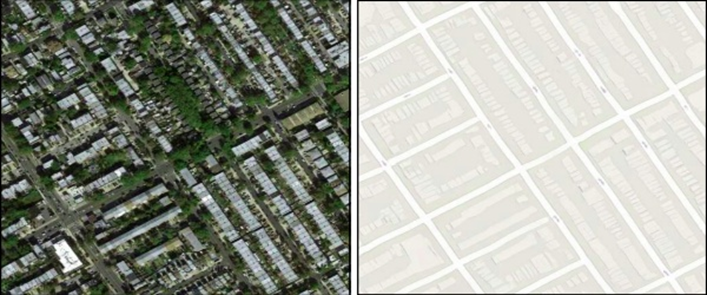

Рисунок 1. Слева – изображение, полученное со спутника. Справа – сгенерированное схематическое представление карты.

## Пример набора данных
• http://efrosgans.eecs.berkeley.edu/pix2pix/datasets/

## Предлагаемые архитектуры
• pix2pix (https://arxiv.org/abs/1611.07004)

---
### Источники
"ПРАКТИКУМ
ПО КУРСУ «ТЕХНОЛОГИИ ИСКУССТВЕННОГО ИНТЕЛЛЕКТА И НЕЙРОСЕТЕВОЙ АНАЛИЗ ДАННЫХ»", авторы: Н.С. Давыдов, А.В. Никоноров

## 1. Библиотеки и параметры

In [1]:
import copy, time, json, random, tarfile, urllib.request
from pathlib import Path

import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

SIZE = 256             # размер картинок для сети
LOAD_SIZE = 286        # при обучении сначала растягиваем до 286, потом вырезаем случайные 256x256
BATCH = 4
LR_RATE = 2e-4
LAMBDA_L1 = 100        # вес L1 относительно состязательной ошибки
EPOCHS = 100
LIMIT = 0              # 0 = все пары (ненулевое значение нужно только для быстрой проверки кода)

DATA_DIR = Path('data')
print('Устройство:', device, '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else '')

Устройство: cuda | NVIDIA GeForce RTX 3080


## 2. Данные

Набор `maps` (около 240 МБ): папки `train` (1096 файлов) и `val` (1098 файлов). В каждом файле слева снимок, справа карта, разрезаем пополам. Из `train` берем 90 % на обучение и 10 % на проверку (val), а папку `val` из архива используем как тест (test). Все пары загружаем в память.

In [2]:
maps_dir = DATA_DIR / 'maps'
if not maps_dir.exists():
    DATA_DIR.mkdir(exist_ok=True)
    arc = DATA_DIR / 'maps.tar.gz'
    if not arc.exists():
        urllib.request.urlretrieve('https://efrosgans.eecs.berkeley.edu/pix2pix/datasets/maps.tar.gz', arc)
    with tarfile.open(arc) as t:
        t.extractall(DATA_DIR, filter='data')

train_all = sorted((maps_dir / 'train').glob('*.jpg'))
test_files = sorted((maps_dir / 'val').glob('*.jpg'))
random.Random(SEED).shuffle(train_all)
n_val = round(len(train_all) * 0.1)
val_files, train_files = train_all[:n_val], train_all[n_val:]
if LIMIT:
    train_files, val_files, test_files = train_files[:LIMIT], val_files[:LIMIT], test_files[:LIMIT]
print('train:', len(train_files), 'val:', len(val_files), 'test:', len(test_files))

def load_pairs(files, size):
    # каждый файл: слева снимок, справа карта -> два массива uint8 (N, 3, size, size)
    sat, mp = [], []
    for f in files:
        im = Image.open(f).convert('RGB')
        w, h = im.size
        sat.append(np.array(im.crop((0, 0, w // 2, h)).resize((size, size), Image.BICUBIC)))
        mp.append(np.array(im.crop((w // 2, 0, w, h)).resize((size, size), Image.BICUBIC)))
    to_t = lambda a: torch.from_numpy(np.stack(a)).permute(0, 3, 1, 2).contiguous()
    return to_t(sat), to_t(mp)

t0 = time.time()
train_sat, train_map = load_pairs(train_files, LOAD_SIZE)
val_sat, val_map = load_pairs(val_files, SIZE)
test_sat, test_map = load_pairs(test_files, SIZE)
print('загружено за %.0f с, train: %s' % (time.time() - t0, tuple(train_sat.shape)))

train: 986 val: 110 test: 1098


загружено за 19 с, train: (986, 3, 286, 286)


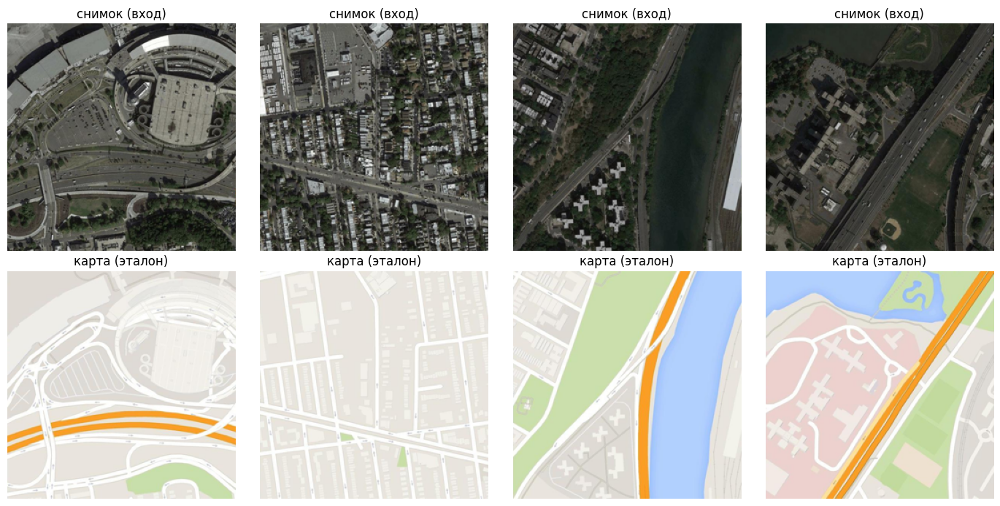

In [3]:
norm = lambda x: x.float() / 127.5 - 1          # uint8 [0,255] -> float [-1,1]
denorm_u8 = lambda x: ((x.clamp(-1, 1) + 1) * 127.5).round().byte().permute(0, 2, 3, 1).cpu().numpy()   # -> uint8 (B,H,W,3)

class TrainSet(Dataset):
    # случайный кусок 256x256 из 286x286 + случайное отражение; одинаково для снимка и карты
    def __len__(self):
        return len(train_sat)
    def __getitem__(self, i):
        x, y = random.randint(0, LOAD_SIZE - SIZE), random.randint(0, LOAD_SIZE - SIZE)
        s, m = train_sat[i, :, y:y + SIZE, x:x + SIZE], train_map[i, :, y:y + SIZE, x:x + SIZE]
        if random.random() < 0.5:
            s, m = s.flip(-1), m.flip(-1)
        return norm(s), norm(m)

train_loader = DataLoader(TrainSet(), batch_size=BATCH, shuffle=True, drop_last=True)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for k in range(4):
    axes[0, k].imshow(val_sat[k].permute(1, 2, 0)); axes[0, k].set_title('снимок (вход)')
    axes[1, k].imshow(val_map[k].permute(1, 2, 0)); axes[1, k].set_title('карта (эталон)')
for a in axes.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

## 3. Метрики

Сравниваем сгенерированную карту $\hat{y}$ с эталонной $y$.

**L1** (меньше — лучше), значения пикселей в $[0,1]$:

$$L_1 = \frac{1}{N}\sum_{i=1}^{N}|\hat{y}_i - y_i|$$

**PSNR** (дБ) и **SSIM** (от 0 до 1), больше — лучше:

$$\mathrm{PSNR} = 10\log_{10}\frac{\mathrm{MAX}^2}{\mathrm{MSE}}, \qquad \mathrm{SSIM} = \frac{(2\mu_x\mu_y + C_1)(2\sigma_{xy} + C_2)}{(\mu_x^2 + \mu_y^2 + C_1)(\sigma_x^2 + \sigma_y^2 + C_2)}$$

$N$ — число значений пикселей, $\mathrm{MAX}=255$, $\mathrm{MSE}$ — средний квадрат ошибки, $\mu$ — средние в окне, $\sigma^2$ — дисперсии, $\sigma_{xy}$ — ковариация, $C_1, C_2$ — малые константы.

**Резкость** — дисперсия лапласиана серого изображения: чем больше, тем четче границы. Нужна только для сравнения «размыто / четко».

In [4]:
def sharpness(img_u8):
    return cv2.Laplacian(cv2.cvtColor(img_u8, cv2.COLOR_RGB2GRAY), cv2.CV_64F).var()

@torch.no_grad()
def val_scores(G):
    # L1 (шкала [0,1]) и PSNR на val, на GPU
    G.eval(); l1 = psnr = 0.0
    for i in range(0, len(val_sat), 8):
        x, y = norm(val_sat[i:i + 8]).to(device), norm(val_map[i:i + 8]).to(device)
        d = (G(x) - y) / 2                                   # разница в шкале [0,1]
        l1 += d.abs().mean(dim=(1, 2, 3)).sum().item()
        psnr += (10 * torch.log10(1 / (d ** 2).mean(dim=(1, 2, 3)).clamp_min(1e-10))).sum().item()
    return l1 / len(val_sat), psnr / len(val_sat)

def test_metrics(pred_u8, true_u8):
    l1 = float(np.mean(np.abs(pred_u8.astype(np.float32) - true_u8.astype(np.float32))) / 255)
    p = np.mean([peak_signal_noise_ratio(t, s, data_range=255) for s, t in zip(pred_u8, true_u8)])
    s = np.mean([structural_similarity(t, s_, channel_axis=2, data_range=255) for s_, t in zip(pred_u8, true_u8)])
    sh = np.mean([sharpness(x) for x in pred_u8])
    return {'L1': l1, 'PSNR': float(p), 'SSIM': float(s), 'Резкость': float(sh)}

## 4. Сеть

Архитектура pix2pix. **Генератор — U-Net:** снимок 256×256 сжимается восемью свертками до 1×1 и разворачивается обратно, между слоями одного размера идут skip-связи; в первых трех слоях разворота Dropout 0.5, выход Tanh в $[-1,1]$. **Дискриминатор — PatchGAN 70×70:** получает снимок и карту вместе и выдает сетку 30×30 ответов «настоящая / сгенерированная». Ошибка генератора: $L_G = L_{GAN} + 100 \cdot L_1$.

In [5]:
class Down(nn.Sequential):
    def __init__(self, c_in, c_out, norm=True):
        layers = [nn.Conv2d(c_in, c_out, 4, 2, 1, bias=False)]
        if norm: layers.append(nn.BatchNorm2d(c_out))
        layers.append(nn.LeakyReLU(0.2, inplace=True))
        super().__init__(*layers)

class Up(nn.Sequential):
    def __init__(self, c_in, c_out, dropout=False):
        layers = [nn.ConvTranspose2d(c_in, c_out, 4, 2, 1, bias=False), nn.BatchNorm2d(c_out)]
        if dropout: layers.append(nn.Dropout(0.5))
        layers.append(nn.ReLU(inplace=True))
        super().__init__(*layers)

class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.downs = nn.ModuleList([Down(3, 64, norm=False), Down(64, 128), Down(128, 256), Down(256, 512),
                                    Down(512, 512), Down(512, 512), Down(512, 512), Down(512, 512, norm=False)])
        self.ups = nn.ModuleList([Up(512, 512, True), Up(1024, 512, True), Up(1024, 512, True), Up(1024, 512),
                                  Up(1024, 256), Up(512, 128), Up(256, 64)])
        self.final = nn.Sequential(nn.ConvTranspose2d(128, 3, 4, 2, 1), nn.Tanh())

    def forward(self, x):
        skips = []
        for d in self.downs:
            x = d(x); skips.append(x)
        x = self.ups[0](skips[-1])
        for up, s in zip(self.ups[1:], reversed(skips[1:-1])):
            x = up(torch.cat([x, s], 1))
        return self.final(torch.cat([x, skips[0]], 1))

class PatchGAN(nn.Module):
    def __init__(self, sn=False):
        super().__init__()
        def conv(c_in, c_out, stride, bias):
            c = nn.Conv2d(c_in, c_out, 4, stride, 1, bias=bias)
            nn.init.normal_(c.weight, 0.0, 0.02)
            return nn.utils.spectral_norm(c) if sn else c      # sn=True: spectral normalization весов
        def block(c_in, c_out, stride, norm=True):
            norm = norm and not sn                              # со spectral norm BatchNorm в дискриминаторе не нужен
            l = [conv(c_in, c_out, stride, not norm)]
            if norm: l.append(nn.BatchNorm2d(c_out))
            l.append(nn.LeakyReLU(0.2, inplace=True))
            return l
        self.net = nn.Sequential(*block(6, 64, 2, False), *block(64, 128, 2), *block(128, 256, 2), *block(256, 512, 1),
                                 conv(512, 1, 1, True))
    def forward(self, sat, mp):
        return self.net(torch.cat([sat, mp], 1))

def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)

g_try = UNet().to(device)
print('Параметров: генератор %.1f млн, дискриминатор %.2f млн' % (
    sum(p.numel() for p in g_try.parameters()) / 1e6, sum(p.numel() for p in PatchGAN().parameters()) / 1e6))
print('Размеры: генератор', tuple(g_try(torch.zeros(2, 3, 256, 256, device=device)).shape),
      ', дискриминатор', tuple(PatchGAN().to(device)(torch.zeros(2, 3, 256, 256, device=device), torch.zeros(2, 3, 256, 256, device=device)).shape))
del g_try

Параметров: генератор 54.4 млн, дискриминатор 2.77 млн


Размеры: генератор (2, 3, 256, 256) , дискриминатор (2, 1, 30, 30)


## 5. Обучение

Одна функция обучает обе модели: при `use_gan=False` дискриминатора нет, и генератор учится только по L1. Adam, `lr=2e-4`, `betas=(0.5, 0.999)`, batch 4, 100 эпох: первую половину lr постоянный, во второй линейно падает до нуля. Берем веса последней эпохи.

In [6]:
Path('weights').mkdir(exist_ok=True)

def train(use_gan, tag, lr=LR_RATE, betas=(0.5, 0.999), lam_l1=LAMBDA_L1, loader=None, log_every=1,
          epochs=EPOCHS, gan_loss='bce', sn=False, ema_decay=None):
    torch.manual_seed(SEED); random.seed(SEED)
    if loader is None:
        loader = train_loader
    snap_epochs = sorted({1, 5, 20, epochs // 2, epochs} & set(range(1, epochs + 1)))
    G = UNet().to(device); G.apply(init_weights)
    G_ema = copy.deepcopy(G) if ema_decay else None       # усредненные веса генератора (EMA)
    opt_g = torch.optim.Adam(G.parameters(), lr=lr, betas=betas)
    lam = lambda ep: 1.0 if ep < epochs // 2 else max(0.0, (epochs - ep) / (epochs - epochs // 2))
    scheds = [torch.optim.lr_scheduler.LambdaLR(opt_g, lam)]
    if use_gan:
        D = PatchGAN(sn=sn).to(device)
        if not sn: D.apply(init_weights)
        opt_d = torch.optim.Adam(D.parameters(), lr=lr, betas=betas)
        scheds.append(torch.optim.lr_scheduler.LambdaLR(opt_d, lam))
        crit = nn.MSELoss() if gan_loss == 'lsgan' else nn.BCEWithLogitsLoss()    # LSGAN: квадрат ошибки вместо кросс-энтропии
    hist = {'g_gan': [], 'g_l1': [], 'd_loss': [], 'val_l1': [], 'val_psnr': []}
    snaps = {}
    t0 = time.time()
    for ep in range(1, epochs + 1):
        G.train()
        acc = np.zeros(3)
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            fake = G(x)
            l_gan = l_d = torch.zeros(())
            if use_gan:
                D.train()
                p_real, p_fake = D(x, y), D(x, fake.detach())
                l_d = (crit(p_real, torch.ones_like(p_real)) + crit(p_fake, torch.zeros_like(p_fake))) / 2
                opt_d.zero_grad(); l_d.backward(); opt_d.step()
                p_fake = D(x, fake)
                l_gan = crit(p_fake, torch.ones_like(p_fake))
            l_l1 = F.l1_loss(fake, y)
            loss_g = l_gan + lam_l1 * l_l1
            opt_g.zero_grad(); loss_g.backward(); opt_g.step()
            if ema_decay:
                with torch.no_grad():
                    for pe, p_ in zip(G_ema.parameters(), G.parameters()): pe.mul_(ema_decay).add_(p_, alpha=1 - ema_decay)
                    for be, b_ in zip(G_ema.buffers(), G.buffers()): be.copy_(b_)
            acc += [l_gan.item(), l_l1.item(), l_d.item()]
        acc /= len(loader)
        for s in scheds: s.step()
        G_eval = G_ema if ema_decay else G                    # проверяем усредненный генератор, если он есть
        v_l1, v_psnr = val_scores(G_eval)
        for k, v in zip(['g_gan', 'g_l1', 'd_loss'], acc): hist[k].append(float(v))
        hist['val_l1'].append(v_l1); hist['val_psnr'].append(v_psnr)
        if ep in snap_epochs:
            G_eval.eval()
            with torch.no_grad():
                snaps[ep] = denorm_u8(G_eval(norm(val_sat[:3]).to(device)))
        if ep % log_every == 0 or ep == epochs:
            print(f'[{tag}] эпоха {ep:3d}: G_gan={acc[0]:.3f} L1={acc[1]:.4f} D={acc[2]:.3f} | val L1={v_l1:.4f} PSNR={v_psnr:.2f} ({time.time() - t0:.0f} с)')
    G_final = G_ema if ema_decay else G
    torch.save(G_final.state_dict(), f'weights/lr2_{tag}.pt')
    json.dump(hist, open(f'weights/lr2_{tag}_hist.json', 'w'))
    return G_final, hist, snaps

### 5.1. Только L1 (без дискриминатора)

In [7]:
G_l1, hist_l1, snaps_l1 = train(use_gan=False, tag='l1')

[l1] эпоха   1: G_gan=0.000 L1=0.1584 D=0.000 | val L1=0.0673 PSNR=21.81 (6 с)


[l1] эпоха   2: G_gan=0.000 L1=0.1018 D=0.000 | val L1=0.0743 PSNR=20.73 (11 с)


[l1] эпоха   3: G_gan=0.000 L1=0.0954 D=0.000 | val L1=0.0566 PSNR=23.14 (17 с)


[l1] эпоха   4: G_gan=0.000 L1=0.0920 D=0.000 | val L1=0.0476 PSNR=24.12 (22 с)


[l1] эпоха   5: G_gan=0.000 L1=0.0895 D=0.000 | val L1=0.0566 PSNR=22.44 (28 с)


...

[l1] эпоха  96: G_gan=0.000 L1=0.0461 D=0.000 | val L1=0.0254 PSNR=28.29 (531 с)


[l1] эпоха  97: G_gan=0.000 L1=0.0461 D=0.000 | val L1=0.0253 PSNR=28.25 (536 с)


[l1] эпоха  98: G_gan=0.000 L1=0.0458 D=0.000 | val L1=0.0254 PSNR=28.35 (542 с)


[l1] эпоха  99: G_gan=0.000 L1=0.0460 D=0.000 | val L1=0.0252 PSNR=28.37 (548 с)


[l1] эпоха 100: G_gan=0.000 L1=0.0460 D=0.000 | val L1=0.0254 PSNR=28.31 (553 с)


### 5.2. pix2pix (дискриминатор + L1)

In [8]:
G_p2p, hist_p2p, snaps_p2p = train(use_gan=True, tag='pix2pix')

[pix2pix] эпоха   1: G_gan=2.008 L1=0.1600 D=0.427 | val L1=0.0704 PSNR=20.61 (10 с)


[pix2pix] эпоха   2: G_gan=1.734 L1=0.1114 D=0.397 | val L1=0.0909 PSNR=18.51 (19 с)


[pix2pix] эпоха   3: G_gan=1.656 L1=0.1083 D=0.426 | val L1=0.0645 PSNR=20.92 (29 с)


[pix2pix] эпоха   4: G_gan=1.704 L1=0.1059 D=0.429 | val L1=0.0694 PSNR=21.09 (39 с)


[pix2pix] эпоха   5: G_gan=1.593 L1=0.1017 D=0.425 | val L1=0.0478 PSNR=23.60 (49 с)


...

[pix2pix] эпоха  96: G_gan=4.188 L1=0.0677 D=0.043 | val L1=0.0327 PSNR=26.35 (934 с)


[pix2pix] эпоха  97: G_gan=4.275 L1=0.0664 D=0.039 | val L1=0.0325 PSNR=26.44 (944 с)


[pix2pix] эпоха  98: G_gan=4.287 L1=0.0669 D=0.040 | val L1=0.0324 PSNR=26.41 (954 с)


[pix2pix] эпоха  99: G_gan=4.204 L1=0.0669 D=0.036 | val L1=0.0323 PSNR=26.45 (963 с)


[pix2pix] эпоха 100: G_gan=4.336 L1=0.0672 D=0.035 | val L1=0.0325 PSNR=26.42 (973 с)


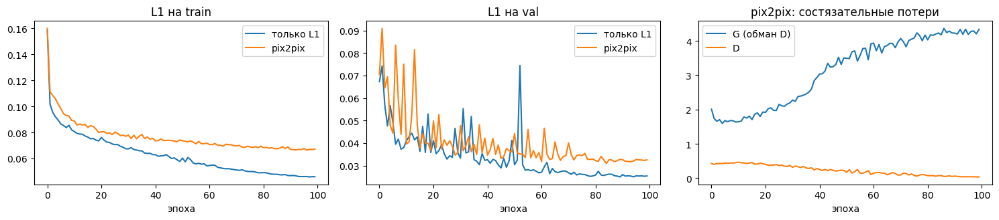

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
ax[0].plot(hist_l1['g_l1'], label='только L1'); ax[0].plot(hist_p2p['g_l1'], label='pix2pix')
ax[0].set_title('L1 на train'); ax[0].legend(); ax[0].set_xlabel('эпоха')
ax[1].plot(hist_l1['val_l1'], label='только L1'); ax[1].plot(hist_p2p['val_l1'], label='pix2pix')
ax[1].set_title('L1 на val'); ax[1].legend(); ax[1].set_xlabel('эпоха')
ax[2].plot(hist_p2p['g_gan'], label='G (обман D)'); ax[2].plot(hist_p2p['d_loss'], label='D')
ax[2].set_title('pix2pix: состязательные потери'); ax[2].legend(); ax[2].set_xlabel('эпоха')
plt.tight_layout(); plt.show()

**Вывод.** L1 на train и val падает у обеих моделей, у pix2pix он выше (на train 0.067 против 0.046), потому что часть усилий уходит на обман дискриминатора. Дискриминатор постепенно выигрывает: его потеря упала с 0.43 до 0.035, а ошибка генератора по обману D выросла с 2 до 4.3.

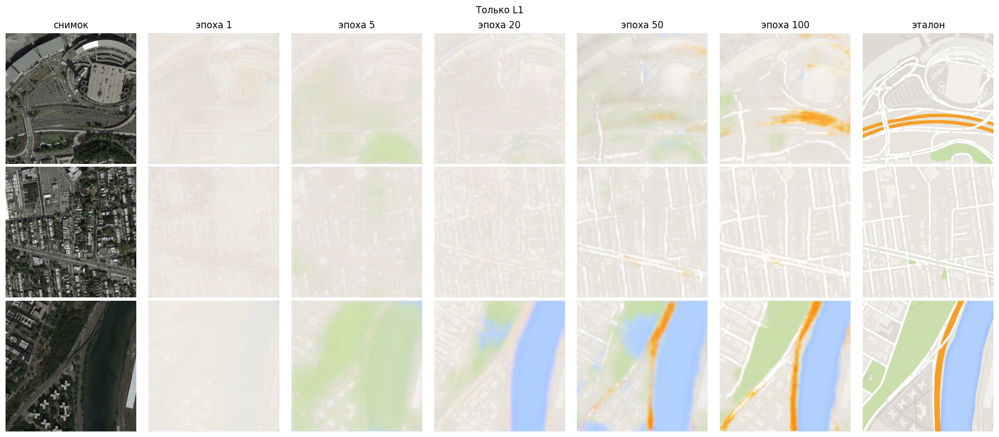

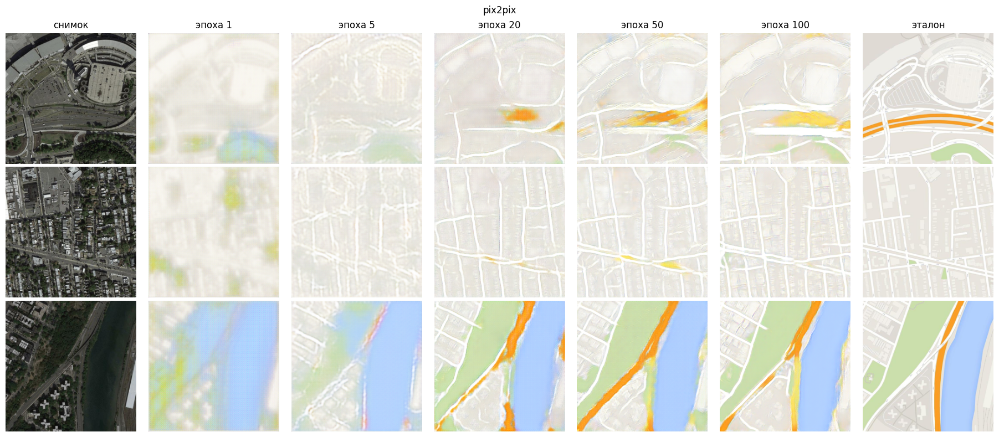

In [10]:
# как менялась карта по ходу обучения (3 картинки val)
def show_snaps(snaps, title):
    eps = sorted(snaps)
    fig, axes = plt.subplots(3, len(eps) + 2, figsize=(2.6 * (len(eps) + 2), 8))
    for r in range(3):
        axes[r, 0].imshow(val_sat[r].permute(1, 2, 0)); axes[r, 0].set_title('снимок' if r == 0 else '')
        for c, e in enumerate(eps):
            axes[r, c + 1].imshow(snaps[e][r]); axes[r, c + 1].set_title(f'эпоха {e}' if r == 0 else '')
        axes[r, -1].imshow(val_map[r].permute(1, 2, 0)); axes[r, -1].set_title('эталон' if r == 0 else '')
    for a in axes.ravel(): a.axis('off')
    fig.suptitle(title); plt.tight_layout(); plt.show()

show_snaps(snaps_l1, 'Только L1')
show_snaps(snaps_p2p, 'pix2pix')

**Вывод.** pix2pix рисует все более четкую карту: на 1-й эпохе размытые пятна, к 5-й появляются контуры, к 20-й дороги, вода и парки нужного цвета. Дальше меняются в основном детали, оранжевые магистрали получаются неточно.

## 6. Результаты на тесте

Модель             L1  PSNR, дБ     SSIM   Резкость
Только L1      0.0272     27.08   0.7388       16.2
pix2pix        0.0345     25.48   0.6259      226.4
Эталон                                        198.3


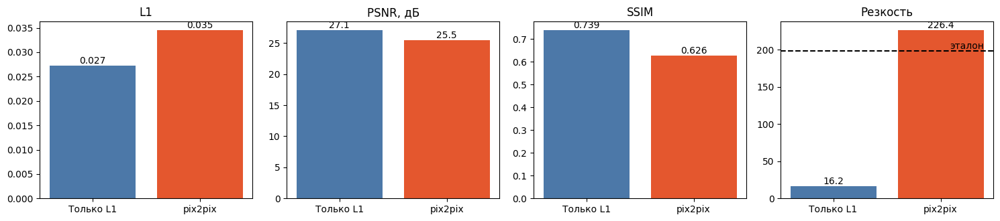

In [8]:
@torch.no_grad()
def predict(G, sat_u8):
    G.eval()
    out = [G(norm(sat_u8[i:i + 8]).to(device)) for i in range(0, len(sat_u8), 8)]
    return denorm_u8(torch.cat(out))

test_true = test_map.permute(0, 2, 3, 1).numpy()
preds = {'Только L1': predict(G_l1, test_sat), 'pix2pix': predict(G_p2p, test_sat)}
res = {name: test_metrics(p, test_true) for name, p in preds.items()}
res['Эталон'] = {'Резкость': float(np.mean([sharpness(x) for x in test_true]))}

print(f'{"Модель":<12}{"L1":>9}{"PSNR, дБ":>10}{"SSIM":>9}{"Резкость":>11}')
for name in ['Только L1', 'pix2pix']:
    r = res[name]; print(f'{name:<12}{r["L1"]:>9.4f}{r["PSNR"]:>10.2f}{r["SSIM"]:>9.4f}{r["Резкость"]:>11.1f}')
print(f'{"Эталон":<12}{"":>9}{"":>10}{"":>9}{res["Эталон"]["Резкость"]:>11.1f}')
json.dump(res, open('weights/lr2_results.json', 'w'), ensure_ascii=False)

fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
for a, key in zip(ax, ['L1', 'PSNR', 'SSIM', 'Резкость']):
    vals = [res[n][key] for n in ['Только L1', 'pix2pix']]
    a.bar(['Только L1', 'pix2pix'], vals, color=['#4C78A8', '#E4572E']); a.set_title(key + (', дБ' if key == 'PSNR' else ''))
    for i, v in enumerate(vals): a.text(i, v, f'{v:.3f}' if key in ('L1', 'SSIM') else f'{v:.1f}', ha='center', va='bottom')
ax[3].axhline(res['Эталон']['Резкость'], color='k', ls='--'); ax[3].text(1.4, res['Эталон']['Резкость'], 'эталон', ha='right', va='bottom')
plt.tight_layout(); plt.show()

**Вывод.** По L1, PSNR и SSIM лучше модель только на L1 (0.027, 27.08 дБ, 0.739 против 0.035, 25.48 дБ, 0.626 у pix2pix). Зато резкость у нее 16, а у pix2pix 226 при эталонных 198: карта L1-модели размыта.

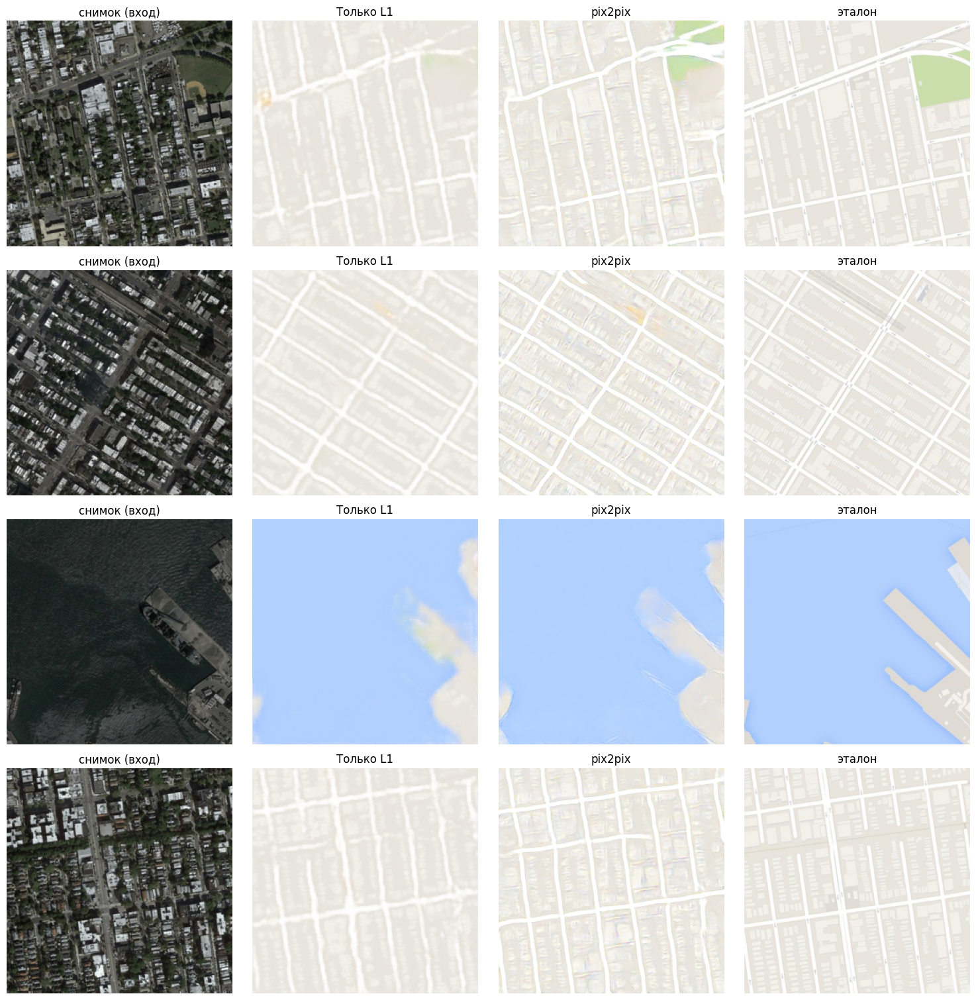

In [13]:
idxs = [0, 10, 100, 500] if len(test_true) > 500 else list(range(min(4, len(test_true))))
fig, axes = plt.subplots(len(idxs), 4, figsize=(15, 3.8 * len(idxs)))
for r, i in enumerate(idxs):
    for c, (name, img) in enumerate([('снимок (вход)', test_sat[i].permute(1, 2, 0).numpy()), ('Только L1', preds['Только L1'][i]),
                                     ('pix2pix', preds['pix2pix'][i]), ('эталон', test_true[i])]):
        axes[r, c].imshow(img); axes[r, c].set_title(name); axes[r, c].axis('off')
plt.tight_layout(); plt.show()

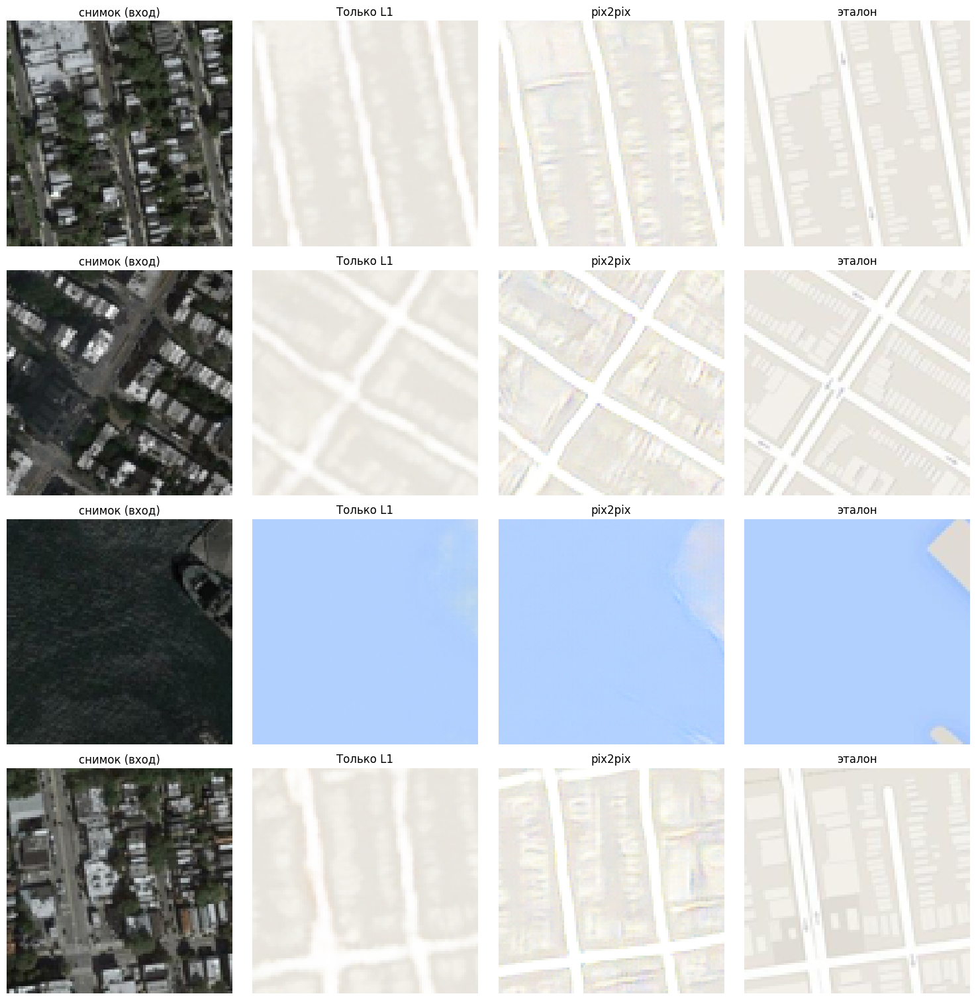

In [14]:
# приближенный фрагмент 96x96 тех же картинок (видно, чем отличаются границы)
fig, axes = plt.subplots(len(idxs), 4, figsize=(15, 3.8 * len(idxs)))
for r, i in enumerate(idxs):
    for c, (name, img) in enumerate([('снимок (вход)', test_sat[i].permute(1, 2, 0).numpy()), ('Только L1', preds['Только L1'][i]),
                                     ('pix2pix', preds['pix2pix'][i]), ('эталон', test_true[i])]):
        axes[r, c].imshow(img[80:176, 80:176], interpolation='nearest'); axes[r, c].set_title(name); axes[r, c].axis('off')
plt.tight_layout(); plt.show()

**Вывод.** L1-модель рисует дороги широкими мягкими полосами, pix2pix — четкими линиями, но на месте домов добавляет шум. Воду и главные дороги рисуют обе, отдельные дома и подписи не получились ни у одной.

## 7. Первые тесты с обычными параметрами

Обучаем pix2pix с параметрами, которые обычно ставят по умолчанию: Adam с `lr=1e-4` и стандартными `betas=(0.9, 0.999)`, вес L1 равен 10, без случайного сдвига и отражения (берем центральный кусок картинки). Генератор, дискриминатор, batch size и число эпох те же.

In [9]:
class TrainSetPlain(Dataset):
    # без аугментации: центральный кусок 256x256 из 286x286, без отражения
    def __len__(self):
        return len(train_sat)
    def __getitem__(self, i):
        o = (LOAD_SIZE - SIZE) // 2
        return norm(train_sat[i, :, o:o + SIZE, o:o + SIZE]), norm(train_map[i, :, o:o + SIZE, o:o + SIZE])

plain_loader = DataLoader(TrainSetPlain(), batch_size=BATCH, shuffle=True, drop_last=True)
G_p2p_0, hist_p2p_0, _ = train(use_gan=True, tag='pix2pix_0', lr=1e-4, betas=(0.9, 0.999), lam_l1=10, loader=plain_loader, log_every=10)

[pix2pix_0] эпоха  10: G_gan=2.519 L1=0.1907 D=0.262 | val L1=0.5328 PSNR=4.08 (102 с)


[pix2pix_0] эпоха  20: G_gan=2.859 L1=0.1523 D=0.231 | val L1=0.1152 PSNR=16.34 (202 с)


[pix2pix_0] эпоха  30: G_gan=2.481 L1=0.1416 D=0.300 | val L1=0.0699 PSNR=20.17 (292 с)


[pix2pix_0] эпоха  40: G_gan=2.994 L1=0.1451 D=0.199 | val L1=0.0710 PSNR=20.43 (389 с)


[pix2pix_0] эпоха  50: G_gan=3.033 L1=0.1446 D=0.258 | val L1=0.0779 PSNR=20.19 (481 с)


[pix2pix_0] эпоха  60: G_gan=2.603 L1=0.1184 D=0.234 | val L1=0.0952 PSNR=18.02 (574 с)


[pix2pix_0] эпоха  70: G_gan=2.775 L1=0.1214 D=0.207 | val L1=0.0477 PSNR=23.22 (670 с)


[pix2pix_0] эпоха  80: G_gan=2.495 L1=0.1071 D=0.215 | val L1=0.0500 PSNR=23.11 (775 с)


[pix2pix_0] эпоха  90: G_gan=2.384 L1=0.1074 D=0.219 | val L1=0.0498 PSNR=23.15 (874 с)


[pix2pix_0] эпоха 100: G_gan=2.464 L1=0.1068 D=0.172 | val L1=0.0512 PSNR=22.52 (965 с)


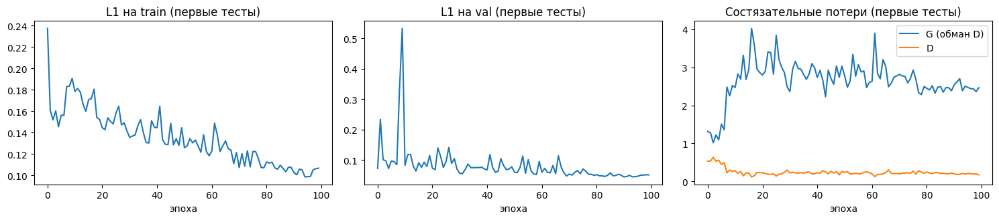

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
ax[0].plot(hist_p2p_0['g_l1']); ax[0].set_title('L1 на train (первые тесты)'); ax[0].set_xlabel('эпоха')
ax[1].plot(hist_p2p_0['val_l1']); ax[1].set_title('L1 на val (первые тесты)'); ax[1].set_xlabel('эпоха')
ax[2].plot(hist_p2p_0['g_gan'], label='G (обман D)'); ax[2].plot(hist_p2p_0['d_loss'], label='D')
ax[2].set_title('Состязательные потери (первые тесты)'); ax[2].legend(); ax[2].set_xlabel('эпоха')
plt.tight_layout(); plt.show()

Модель                         L1  PSNR, дБ     SSIM   Резкость
pix2pix, первые тесты      0.0403     24.60   0.5648      141.5
pix2pix, по статье         0.0345     25.48   0.6259      226.4
Только L1                  0.0272     27.08   0.7388       16.2
Эталон                                                    198.3


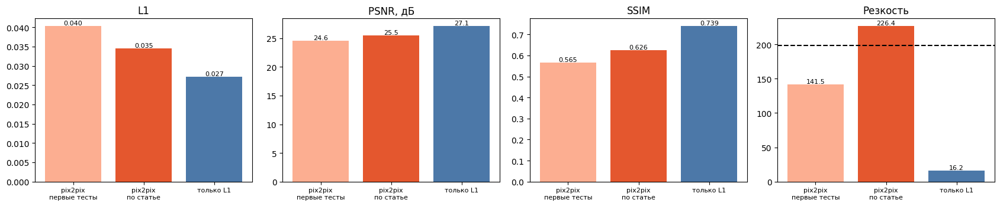

In [11]:
preds['pix2pix 0'] = predict(G_p2p_0, test_sat)
res['pix2pix 0'] = test_metrics(preds['pix2pix 0'], test_true)

order = ['pix2pix 0', 'pix2pix', 'Только L1']
labels = {'pix2pix 0': 'pix2pix, первые тесты', 'pix2pix': 'pix2pix, по статье', 'Только L1': 'Только L1'}
print(f'{"Модель":<24}{"L1":>9}{"PSNR, дБ":>10}{"SSIM":>9}{"Резкость":>11}')
for name in order:
    r = res[name]; print(f'{labels[name]:<24}{r["L1"]:>9.4f}{r["PSNR"]:>10.2f}{r["SSIM"]:>9.4f}{r["Резкость"]:>11.1f}')
print(f'{"Эталон":<24}{"":>9}{"":>10}{"":>9}{res["Эталон"]["Резкость"]:>11.1f}')
json.dump(res, open('weights/lr2_results.json', 'w'), ensure_ascii=False)

fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
for a, key in zip(ax, ['L1', 'PSNR', 'SSIM', 'Резкость']):
    vals = [res[n][key] for n in order]
    a.bar(range(3), vals, color=['#fcae91', '#E4572E', '#4C78A8']); a.set_title(key + (', дБ' if key == 'PSNR' else ''))
    a.set_xticks(range(3)); a.set_xticklabels(['pix2pix\nпервые тесты', 'pix2pix\nпо статье', 'только L1'], fontsize=8)
    for i, v in enumerate(vals): a.text(i, v, f'{v:.3f}' if key in ('L1', 'SSIM') else f'{v:.1f}', ha='center', va='bottom', fontsize=8)
ax[3].axhline(res['Эталон']['Резкость'], color='k', ls='--')
plt.tight_layout(); plt.show()

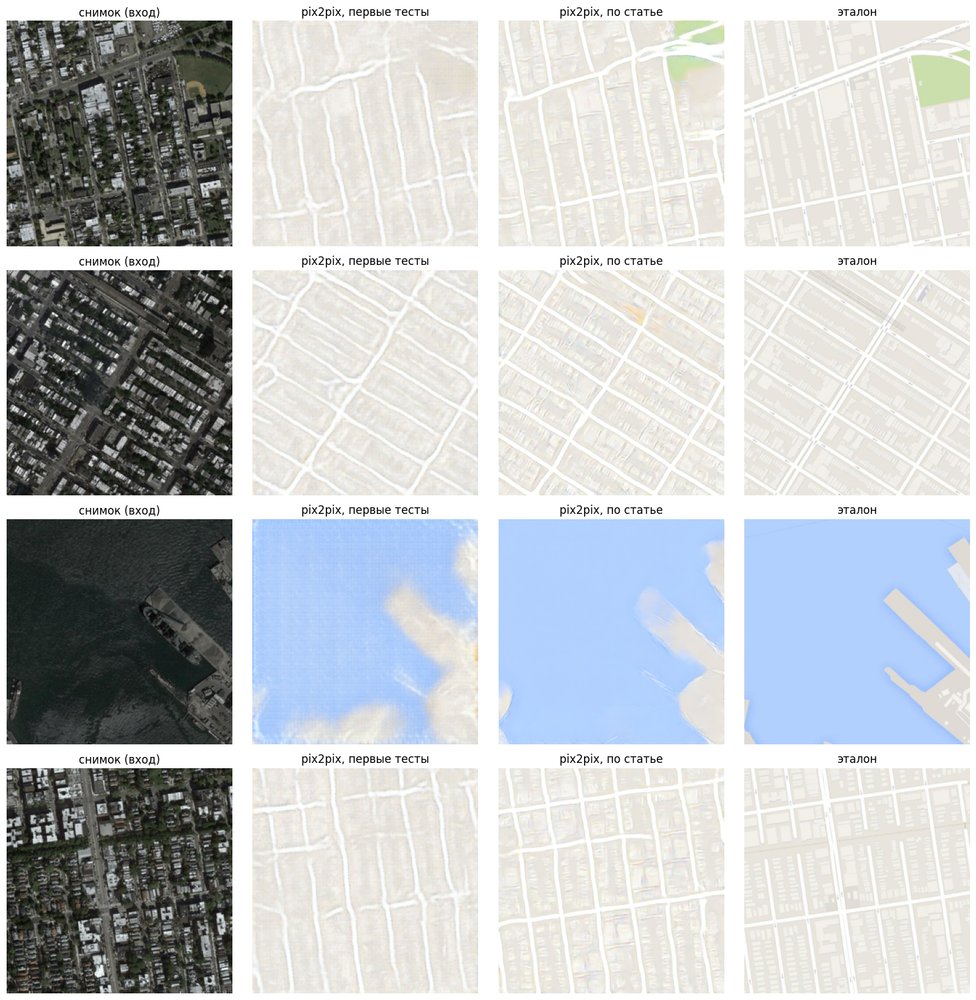

In [12]:
idxs = [0, 10, 100, 500] if len(test_true) > 500 else list(range(min(4, len(test_true))))
cols = [('снимок (вход)', None), ('pix2pix, первые тесты', 'pix2pix 0'), ('pix2pix, по статье', 'pix2pix'), ('эталон', 'true')]
fig, axes = plt.subplots(len(idxs), 4, figsize=(15, 3.8 * len(idxs)))
for r, i in enumerate(idxs):
    for c, (title, key) in enumerate(cols):
        img = test_sat[i].permute(1, 2, 0).numpy() if key is None else (test_true[i] if key == 'true' else preds[key][i])
        axes[r, c].imshow(img); axes[r, c].set_title(title); axes[r, c].axis('off')
plt.tight_layout(); plt.show()

**Вывод.** С обычными параметрами pix2pix получился хуже варианта с параметрами из статьи по всем трем метрикам (L1 0.040 против 0.035, PSNR 24.60 против 25.48 дБ, SSIM 0.565 против 0.626). Дороги у него размытые и неровные, зеленый парк на первой картинке не нарисован, на воде видна мелкая сетка, а качество на val в начале обучения сильно скакало (PSNR 4 дБ на 10-й эпохе).

## 8. Улучшение по более новым статьям

К концу обучения дискриминатор выигрывает: его потеря упала до 0.035, а потеря генератора по D выросла (графики в разделе 5). Из более новых статей (папка `papers/`) берем три простых приема против этого:

- **LSGAN**: в дискриминаторе вместо кросс-энтропии используется квадрат ошибки.
- **Spectral normalization** в дискриминаторе: веса слоев нормируются на наибольшее сингулярное число, BatchNorm в нем не нужен.
- **EMA**: для проверки берутся веса генератора, усредненные по ходу обучения: $\theta_{EMA} \leftarrow \beta\,\theta_{EMA} + (1-\beta)\,\theta$, $\beta = 0.999$.

Число эпох то же (100), чтобы сравнивать только сами приемы. Обучаем два варианта, чтобы видеть, что именно помогло: только EMA (прежняя ошибка) и все три приема вместе.

In [ ]:
G_ema_only, hist_ema_only, _ = train(use_gan=True, tag='p2p_ema', ema_decay=0.999, log_every=10)

[p2p_ema] эпоха  10: G_gan=1.601 L1=0.0895 D=0.448 | val L1=0.0945 PSNR=19.18 (104 с)


[p2p_ema] эпоха  20: G_gan=1.759 L1=0.0822 D=0.419 | val L1=0.0489 PSNR=23.71 (208 с)


[p2p_ema] эпоха  30: G_gan=2.175 L1=0.0778 D=0.362 | val L1=0.0332 PSNR=25.98 (313 с)


[p2p_ema] эпоха  40: G_gan=2.796 L1=0.0753 D=0.291 | val L1=0.0345 PSNR=25.71 (418 с)


[p2p_ema] эпоха  50: G_gan=3.430 L1=0.0738 D=0.184 | val L1=0.0337 PSNR=25.75 (522 с)


[p2p_ema] эпоха  60: G_gan=3.085 L1=0.0696 D=0.182 | val L1=0.0344 PSNR=25.80 (627 с)


[p2p_ema] эпоха  70: G_gan=3.508 L1=0.0681 D=0.150 | val L1=0.0319 PSNR=26.32 (731 с)


[p2p_ema] эпоха  80: G_gan=3.880 L1=0.0676 D=0.091 | val L1=0.0321 PSNR=26.40 (836 с)


[p2p_ema] эпоха  90: G_gan=4.008 L1=0.0667 D=0.064 | val L1=0.0321 PSNR=26.50 (941 с)


[p2p_ema] эпоха 100: G_gan=4.113 L1=0.0652 D=0.042 | val L1=0.0316 PSNR=26.59 (1045 с)


In [ ]:
G_new, hist_new, _ = train(use_gan=True, tag='p2p_new', gan_loss='lsgan', sn=True, ema_decay=0.999, log_every=10)

[p2p_new] эпоха  10: G_gan=0.562 L1=0.0837 D=0.135 | val L1=0.0487 PSNR=23.85 (113 с)


[p2p_new] эпоха  20: G_gan=0.500 L1=0.0734 D=0.149 | val L1=0.0525 PSNR=23.38 (226 с)


[p2p_new] эпоха  30: G_gan=0.475 L1=0.0667 D=0.156 | val L1=0.0407 PSNR=25.30 (339 с)


[p2p_new] эпоха  40: G_gan=0.478 L1=0.0627 D=0.163 | val L1=0.0381 PSNR=25.85 (452 с)


[p2p_new] эпоха  50: G_gan=0.531 L1=0.0585 D=0.140 | val L1=0.0294 PSNR=26.90 (565 с)


[p2p_new] эпоха  60: G_gan=0.554 L1=0.0553 D=0.125 | val L1=0.0274 PSNR=27.57 (678 с)


[p2p_new] эпоха  70: G_gan=0.581 L1=0.0538 D=0.113 | val L1=0.0271 PSNR=27.72 (792 с)


[p2p_new] эпоха  80: G_gan=0.593 L1=0.0508 D=0.104 | val L1=0.0258 PSNR=28.07 (905 с)


[p2p_new] эпоха  90: G_gan=0.604 L1=0.0490 D=0.096 | val L1=0.0253 PSNR=28.10 (1018 с)


[p2p_new] эпоха 100: G_gan=0.610 L1=0.0478 D=0.091 | val L1=0.0249 PSNR=28.20 (1131 с)


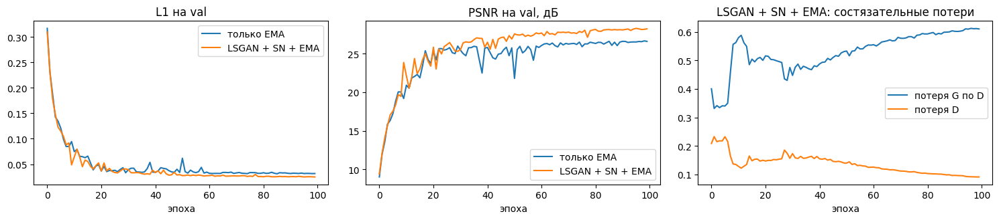

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
ax[0].plot(hist_ema_only['val_l1'], label='только EMA'); ax[0].plot(hist_new['val_l1'], label='LSGAN + SN + EMA')
ax[0].set_title('L1 на val'); ax[0].legend(); ax[0].set_xlabel('эпоха')
ax[1].plot(hist_ema_only['val_psnr'], label='только EMA'); ax[1].plot(hist_new['val_psnr'], label='LSGAN + SN + EMA')
ax[1].set_title('PSNR на val, дБ'); ax[1].legend(); ax[1].set_xlabel('эпоха')
ax[2].plot(hist_new['g_gan'], label='потеря G по D'); ax[2].plot(hist_new['d_loss'], label='потеря D')
ax[2].set_title('LSGAN + SN + EMA: состязательные потери'); ax[2].legend(); ax[2].set_xlabel('эпоха')
plt.tight_layout(); plt.show()

Модель                             L1  PSNR, дБ     SSIM   Резкость
pix2pix, первые тесты          0.0403     24.60   0.5648      141.5
pix2pix, по статье             0.0345     25.48   0.6259      226.4
pix2pix, + EMA                 0.0342     25.58   0.6365      211.4
pix2pix, + LSGAN, SN, EMA      0.0283     26.69   0.7216      106.8
Только L1                      0.0272     27.08   0.7388       16.2
Эталон                                                        198.3


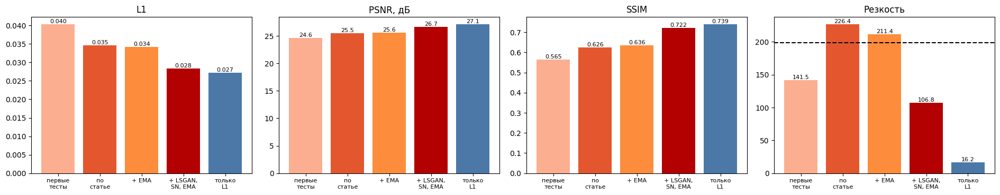

In [ ]:
preds['pix2pix EMA'] = predict(G_ema_only, test_sat)
preds['pix2pix LSGAN+SN+EMA'] = predict(G_new, test_sat)
for name in ('pix2pix EMA', 'pix2pix LSGAN+SN+EMA'):
    res[name] = test_metrics(preds[name], test_true)

order = ['pix2pix 0', 'pix2pix', 'pix2pix EMA', 'pix2pix LSGAN+SN+EMA', 'Только L1']
labels = {'pix2pix 0': 'pix2pix, первые тесты', 'pix2pix': 'pix2pix, по статье', 'pix2pix EMA': 'pix2pix, + EMA',
          'pix2pix LSGAN+SN+EMA': 'pix2pix, + LSGAN, SN, EMA', 'Только L1': 'Только L1'}
print(f'{"Модель":<28}{"L1":>9}{"PSNR, дБ":>10}{"SSIM":>9}{"Резкость":>11}')
for name in order:
    r = res[name]; print(f'{labels[name]:<28}{r["L1"]:>9.4f}{r["PSNR"]:>10.2f}{r["SSIM"]:>9.4f}{r["Резкость"]:>11.1f}')
print(f'{"Эталон":<28}{"":>9}{"":>10}{"":>9}{res["Эталон"]["Резкость"]:>11.1f}')
json.dump(res, open('weights/lr2_results.json', 'w'), ensure_ascii=False)

fig, ax = plt.subplots(1, 4, figsize=(19, 3.8))
for a, key in zip(ax, ['L1', 'PSNR', 'SSIM', 'Резкость']):
    vals = [res[n][key] for n in order]
    a.bar(range(5), vals, color=['#fcae91', '#E4572E', '#fd8d3c', '#b30000', '#4C78A8']); a.set_title(key + (', дБ' if key == 'PSNR' else ''))
    a.set_xticks(range(5)); a.set_xticklabels(['первые\nтесты', 'по\nстатье', '+ EMA', '+ LSGAN,\nSN, EMA', 'только\nL1'], fontsize=8)
    for i, v in enumerate(vals): a.text(i, v, f'{v:.3f}' if key in ('L1', 'SSIM') else f'{v:.1f}', ha='center', va='bottom', fontsize=8)
ax[3].axhline(res['Эталон']['Резкость'], color='k', ls='--')
plt.tight_layout(); plt.show()

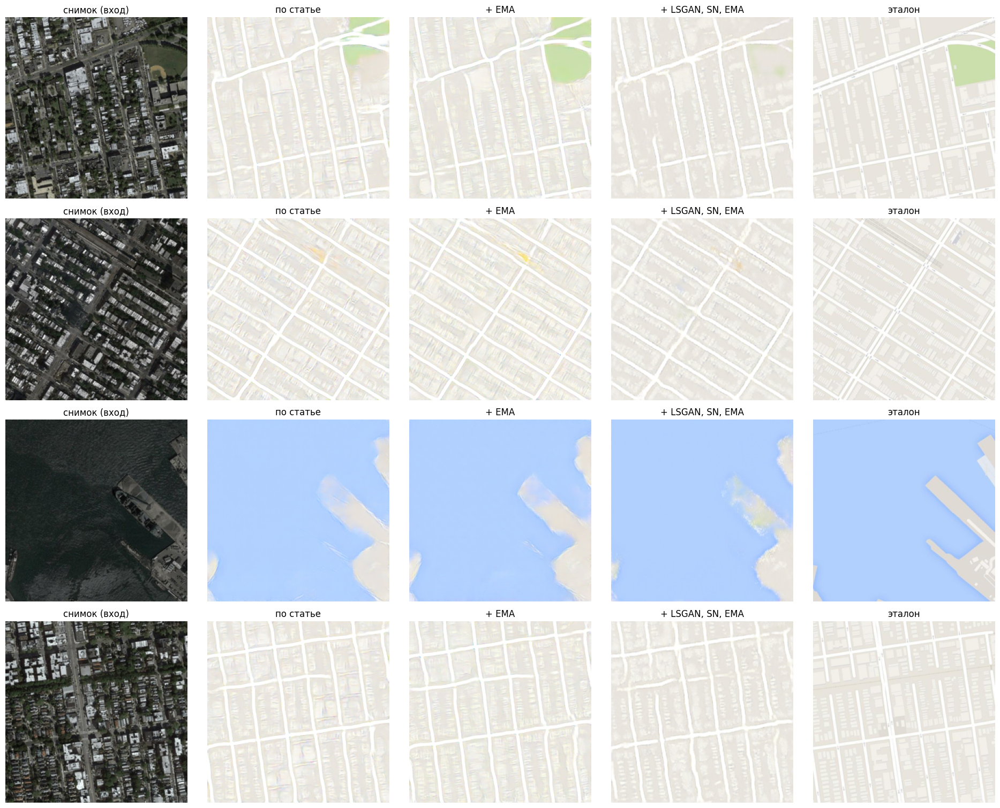

In [ ]:
cols = [('снимок (вход)', None), ('по статье', 'pix2pix'), ('+ EMA', 'pix2pix EMA'), ('+ LSGAN, SN, EMA', 'pix2pix LSGAN+SN+EMA'), ('эталон', 'true')]
fig, axes = plt.subplots(len(idxs), 5, figsize=(19, 3.8 * len(idxs)))
for r, i in enumerate(idxs):
    for c, (title, key) in enumerate(cols):
        img = test_sat[i].permute(1, 2, 0).numpy() if key is None else (test_true[i] if key == 'true' else preds[key][i])
        axes[r, c].imshow(img); axes[r, c].set_title(title); axes[r, c].axis('off')
plt.tight_layout(); plt.show()

**Вывод.** Только EMA почти ничего не изменил (PSNR 25.58 против 25.48 дБ), а LSGAN + SN + EMA дали заметный прирост: L1 0.028 против 0.035, PSNR 26.69 дБ, SSIM 0.722 против 0.626. Качество на val перестало скакать от эпохи к эпохе. Карта стала более гладкой (резкость 107 против 226), яркие цветные пятна уменьшились, но зеленый парк на первой картинке почти пропал.

## 9. Применение к своему снимку

Функция принимает путь к png/bmp/jpg и строит карту. В примере берем снимок из теста.

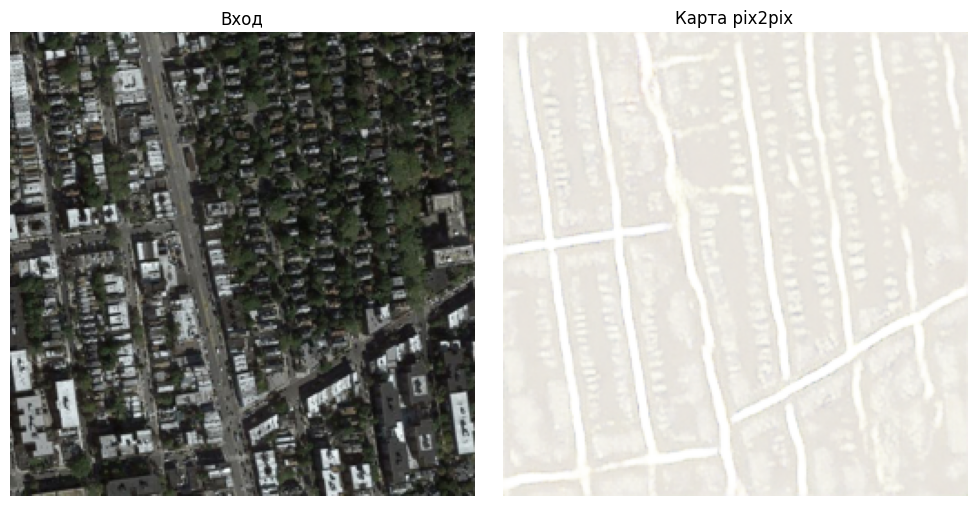

In [15]:
@torch.no_grad()
def map_from_file(in_path, out_path, weights='weights/lr2_p2p_new.pt'):
    g = UNet().to(device); g.load_state_dict(torch.load(weights, map_location=device)); g.eval()
    img = Image.open(in_path).convert('RGB')
    x = torch.from_numpy(np.array(img.resize((SIZE, SIZE), Image.BICUBIC))).permute(2, 0, 1).unsqueeze(0)
    out = Image.fromarray(denorm_u8(g(norm(x).to(device)))[0]).resize(img.size, Image.BICUBIC)
    out.save(out_path)
    return img, out

Image.fromarray(test_sat[1].permute(1, 2, 0).numpy()).save('demo_satellite.png')
sat_img, map_img = map_from_file('demo_satellite.png', 'demo_map.png')
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(sat_img); ax[0].set_title('Вход'); ax[1].imshow(map_img); ax[1].set_title('Карта pix2pix')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

## 10. Выводы

| | L1 | PSNR, дБ | SSIM | Резкость |
|---|---|---|---|---|
| pix2pix, первые тесты | 0.040 | 24.60 | 0.565 | 142 |
| pix2pix, по статье | 0.035 | 25.48 | 0.626 | 226 |
| pix2pix, + EMA | 0.034 | 25.58 | 0.637 | 211 |
| pix2pix, + LSGAN, SN, EMA | 0.028 | 26.69 | 0.722 | 107 |
| Только L1 | 0.027 | 27.08 | 0.739 | 16 |
| Эталон | | | | 198 |

По моим первым тестам с входными параметрами: Adam с lr 1e-4 и betas (0.9, 0.999), вес L1 равен 10, без случайного сдвига и отражения, 100 эпох, получились следующие результаты: L1 0.040, PSNR 24.60 дБ, SSIM 0.565. Дороги на картах размытые, парк не нарисован, на воде видна сетка, а качество на val в первые эпохи сильно скакало.

Для улучшения результатов была рассмотрена статья про pix2pix (папка [papers](papers/)) и выбраны лучшие параметры: Adam с lr 2e-4 и β1 = 0.5, вес L1 равен 100, при обучении картинка растягивается до 286×286 и вырезается случайный кусок 256×256 с отражением. Благодаря этому получилось добиться лучших результатов: L1 0.035, PSNR 25.48 дБ, SSIM 0.626, дороги стали четкими, парк и вода нарисованы. От статьи остались отличия: batch size 4 вместо 1, 100 эпох вместо 200, а на тесте обычный режим eval.

Для дальнейшего улучшения были рассмотрены более новые статьи (папка [papers](papers/): LSGAN, spectral normalization, EMA) и выбраны приемы: квадратичная ошибка LSGAN вместо кросс-энтропии, spectral normalization в дискриминаторе и усреднение весов генератора EMA (β = 0.999). Благодаря этому получилось добиться лучших результатов: L1 0.028, PSNR 26.69 дБ, SSIM 0.722. Обучение стало спокойнее: качество на val почти не скачет, а потери генератора и дискриминатора меняются плавно. Основной прирост дали LSGAN и spectral normalization вместе, EMA сам по себе почти не помог (25.58 дБ и 0.637). Цена улучшения: карта стала более гладкой (резкость 107 против 226 у варианта по статье при эталонных 198), зеленый парк на первой картинке почти пропал.

Модель только на L1 по метрикам остается чуть лучше (L1 0.027, 27.08 дБ, SSIM 0.739), но ее карта размытая (резкость 16 при эталонных 198).